In [1]:
# Import required Libraries

import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats

In [2]:

df = pd.read_csv('../cleaned_dataset.csv')
df.head()

,agecalc_adm,height_cm_adm,weight_kg_adm,muac_mm_adm,hr_bpm_adm,rr_brpm_app_adm,sysbp_mmhg_adm,diasbp_mmhg_adm,temp_c_adm,spo2site1_pc_oxi_adm,...,cookloc_adm,lightfuel_adm,tobacco_adm,bednet_adm,hctpretransfusion_adm,hivstatus_adm,malariastatuspos_adm,caregiver_adm_new,inhospital_mortality,age_group
0,16.8,79.8,11.6,150.0,130.0,23.0,92.0,54.0,36.3,99.0,...,In a separate building/building space used as ...,Electric bulbs (national grid),Never,Always,Yes,HIV negative,No,Mother,0,Toddler (12-23m)
1,46.1,93.0,13.6,151.0,115.0,35.0,72.0,42.0,36.8,92.0,...,In a separate building/building space used as ...,Tadooba,Never,Always,Yes,HIV negative,Yes,Mother,0,Preschool-3 (36-47m)
2,7.9,68.2,8.2,148.0,150.0,56.0,94.0,51.0,37.2,99.0,...,In a separate building/building space used as ...,Tadooba,Never,Always,Yes,HIV negative,No,Mother,0,Baby (6-11m)
3,38.2,95.0,12.0,138.0,134.0,38.0,94.0,57.0,37.6,98.0,...,In the house where you sleep,Electric bulbs (national grid),Never,Always,Yes,HIV negative,Yes,Mother,0,Preschool-3 (36-47m)
4,16.1,83.0,12.0,165.0,163.0,61.0,107.0,73.0,38.7,90.0,...,Outdoors in the open,Electric bulbs (national grid),Never,Sometimes,Yes,HIV negative,Yes,Mother,0,Toddler (12-23m)


In [3]:
df.columns

Index(['agecalc_adm', 'height_cm_adm', 'weight_kg_adm', 'muac_mm_adm',
       'hr_bpm_adm', 'rr_brpm_app_adm', 'sysbp_mmhg_adm', 'diasbp_mmhg_adm',
       'temp_c_adm', 'spo2site1_pc_oxi_adm',
       ...
       'cookloc_adm', 'lightfuel_adm', 'tobacco_adm', 'bednet_adm',
       'hctpretransfusion_adm', 'hivstatus_adm', 'malariastatuspos_adm',
       'caregiver_adm_new', 'inhospital_mortality', 'age_group'],
      dtype='object', length=112)

In [4]:
df.shape

(2686, 112)

In [5]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import confusion_matrix, classification_report,f1_score,make_scorer,accuracy_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import GridSearchCV
from imblearn.over_sampling import SMOTE

In [6]:
#Define the target

X=  X= df.drop('inhospital_mortality',axis=1)

y= df['inhospital_mortality']


In [7]:
# Select numerical and categorical features
numerical_features = X.select_dtypes(include='number').columns
categorical_features = X.select_dtypes(include='object').columns

# Define the column transformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),  # Apply StandardScaler to numerical columns
        ('cat', OneHotEncoder(), categorical_features),
    ]
)

# Fit and transform the data using the preprocessor
transformed_data = preprocessor.fit_transform(X)

# Get the feature names after transformation
numerical_feature_names = list(numerical_features)
categorical_feature_names = list(preprocessor.named_transformers_['cat'].get_feature_names_out())
feature_names = numerical_feature_names + categorical_feature_names

# Convert the transformed data to a DataFrame with column labels
transformed_X = pd.DataFrame(transformed_data, columns=feature_names)

transformed_X.head()

,agecalc_adm,height_cm_adm,weight_kg_adm,muac_mm_adm,hr_bpm_adm,rr_brpm_app_adm,sysbp_mmhg_adm,diasbp_mmhg_adm,temp_c_adm,spo2site1_pc_oxi_adm,...,caregiver_adm_new_Father,caregiver_adm_new_Grandparent,caregiver_adm_new_Mother,caregiver_adm_new_Other,age_group_5 years (60m),age_group_Baby (6-11m),age_group_Preschool-2 (24-35m),age_group_Preschool-3 (36-47m),age_group_Preschool-4 (48-59m),age_group_Toddler (12-23m)
0,-0.331171,0.011930,0.723506,0.748700,-0.439264,-1.560085,-0.416261,-0.053944,-1.161617,0.664525,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,1.913211,1.201135,1.439671,0.811594,-1.026553,-0.752358,-2.101129,-1.144732,-0.665275,-0.431667,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,-1.012912,-1.033129,-0.493975,0.622912,0.343788,0.661165,-0.247775,-0.326641,-0.268202,0.664525,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3,1.308070,1.381318,0.866739,-0.006030,-0.282654,-0.550426,-0.247775,0.218753,0.128871,0.507926,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,-0.384791,0.300222,0.866739,1.692113,0.852771,0.997718,0.847389,1.673138,1.220823,-0.744865,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [8]:
transformed_X.columns

Index(['agecalc_adm', 'height_cm_adm', 'weight_kg_adm', 'muac_mm_adm',
       'hr_bpm_adm', 'rr_brpm_app_adm', 'sysbp_mmhg_adm', 'diasbp_mmhg_adm',
       'temp_c_adm', 'spo2site1_pc_oxi_adm',
       ...
       'caregiver_adm_new_Father', 'caregiver_adm_new_Grandparent',
       'caregiver_adm_new_Mother', 'caregiver_adm_new_Other',
       'age_group_5 years (60m)', 'age_group_Baby (6-11m)',
       'age_group_Preschool-2 (24-35m)', 'age_group_Preschool-3 (36-47m)',
       'age_group_Preschool-4 (48-59m)', 'age_group_Toddler (12-23m)'],
      dtype='object', length=284)

In [9]:
transformed_X.shape

(2686, 284)

In [38]:
# Split the data
X_train, X_test, y_train, y_test = train_test_split(transformed_X, y, test_size=0.2, random_state=42, stratify=y)

#Balancing the data using SMOTE
smote = SMOTE()
X_train, y_train = smote.fit_resample(X_train, y_train)

In [76]:
# Modeling
model = LogisticRegression(random_state=42, max_iter = 1000)
model.fit(X_train, y_train)

# Calculate the training accuracy
train_accuracy = model.score(X_train, y_train)
print("Training Accuracy:", train_accuracy)

# Calculate the testing accuracy
test_accuracy = model.score(X_test, y_test)
print("Testing Accuracy:", test_accuracy)

# Make predictions on the testing data
y_pred = model.predict(X_test)


# Calculate the f1_score
f1=f1_score(y_test, y_pred)
print("f1_score:", f1)

Training Accuracy: 0.9245007306380906
Testing Accuracy: 0.8382899628252788
f1_score: 0.17142857142857143


Classification Report (Default Threshold):
              precision    recall  f1-score   support

           0       0.97      0.86      0.91       514
           1       0.11      0.38      0.17        24

    accuracy                           0.84       538
   macro avg       0.54      0.62      0.54       538
weighted avg       0.93      0.84      0.88       538



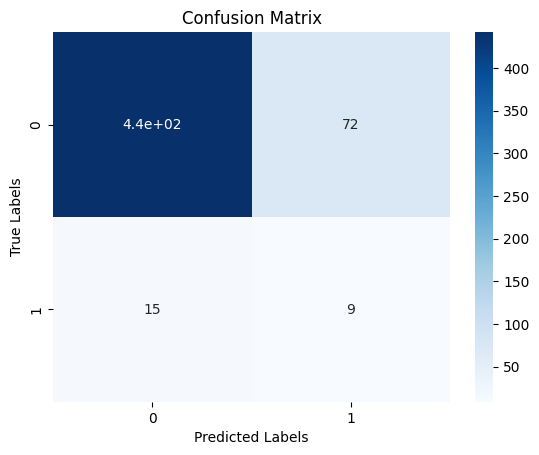

In [78]:
#Classification Report
print("Classification Report (Default Threshold):")
print(classification_report(y_test, y_pred))
# Plot the confusion matrix
confusion_mat = confusion_matrix(y_test, y_pred)
sns.heatmap(confusion_mat, annot=True, cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()

Feature Importance Scores: [1.05428887e-03 1.98354586e-01 4.27185274e-01 5.21041311e-01
 2.14404594e-01 2.11450171e-02 4.90037822e-01 4.60466042e-01
 2.93745893e-01 5.40627956e-01 8.21225772e-01 3.36993164e-01
 2.76303188e-01 4.05247845e-01 7.31536431e-01 4.20378609e-01
 1.04551194e-01 2.71941266e-01 1.60980347e-01 3.92998850e-02
 8.33553759e-01 1.91669130e-01 1.94306053e-01 5.31806519e-01
 5.29169596e-01 1.10769882e+00 2.04401278e-01 6.12691919e-01
 7.02045102e-01 8.46624247e-02 8.20255012e-02 9.68629510e-03
 7.04937163e-03 8.54826364e-01 8.57463287e-01 1.12021781e+00
 1.29033225e+00 1.72751371e-01 1.39478698e+00 3.12407004e-01
 1.07974305e+00 4.66724565e-01 4.69361489e-01 4.22502192e-01
 9.36073329e-01 5.10934214e-01 2.92682535e-01 5.45951090e-02
 6.48719029e-01 1.17360787e+00 2.17224147e+00 1.21516429e-01
 1.95014141e-01 4.51285224e-01 5.61150048e-01 2.09302669e-01
 9.88250155e-02 4.45678781e-02 5.68940608e-02 4.18069323e-02
 2.35088835e-01 2.79532690e-01 1.39971673e-02 1.13602438e-

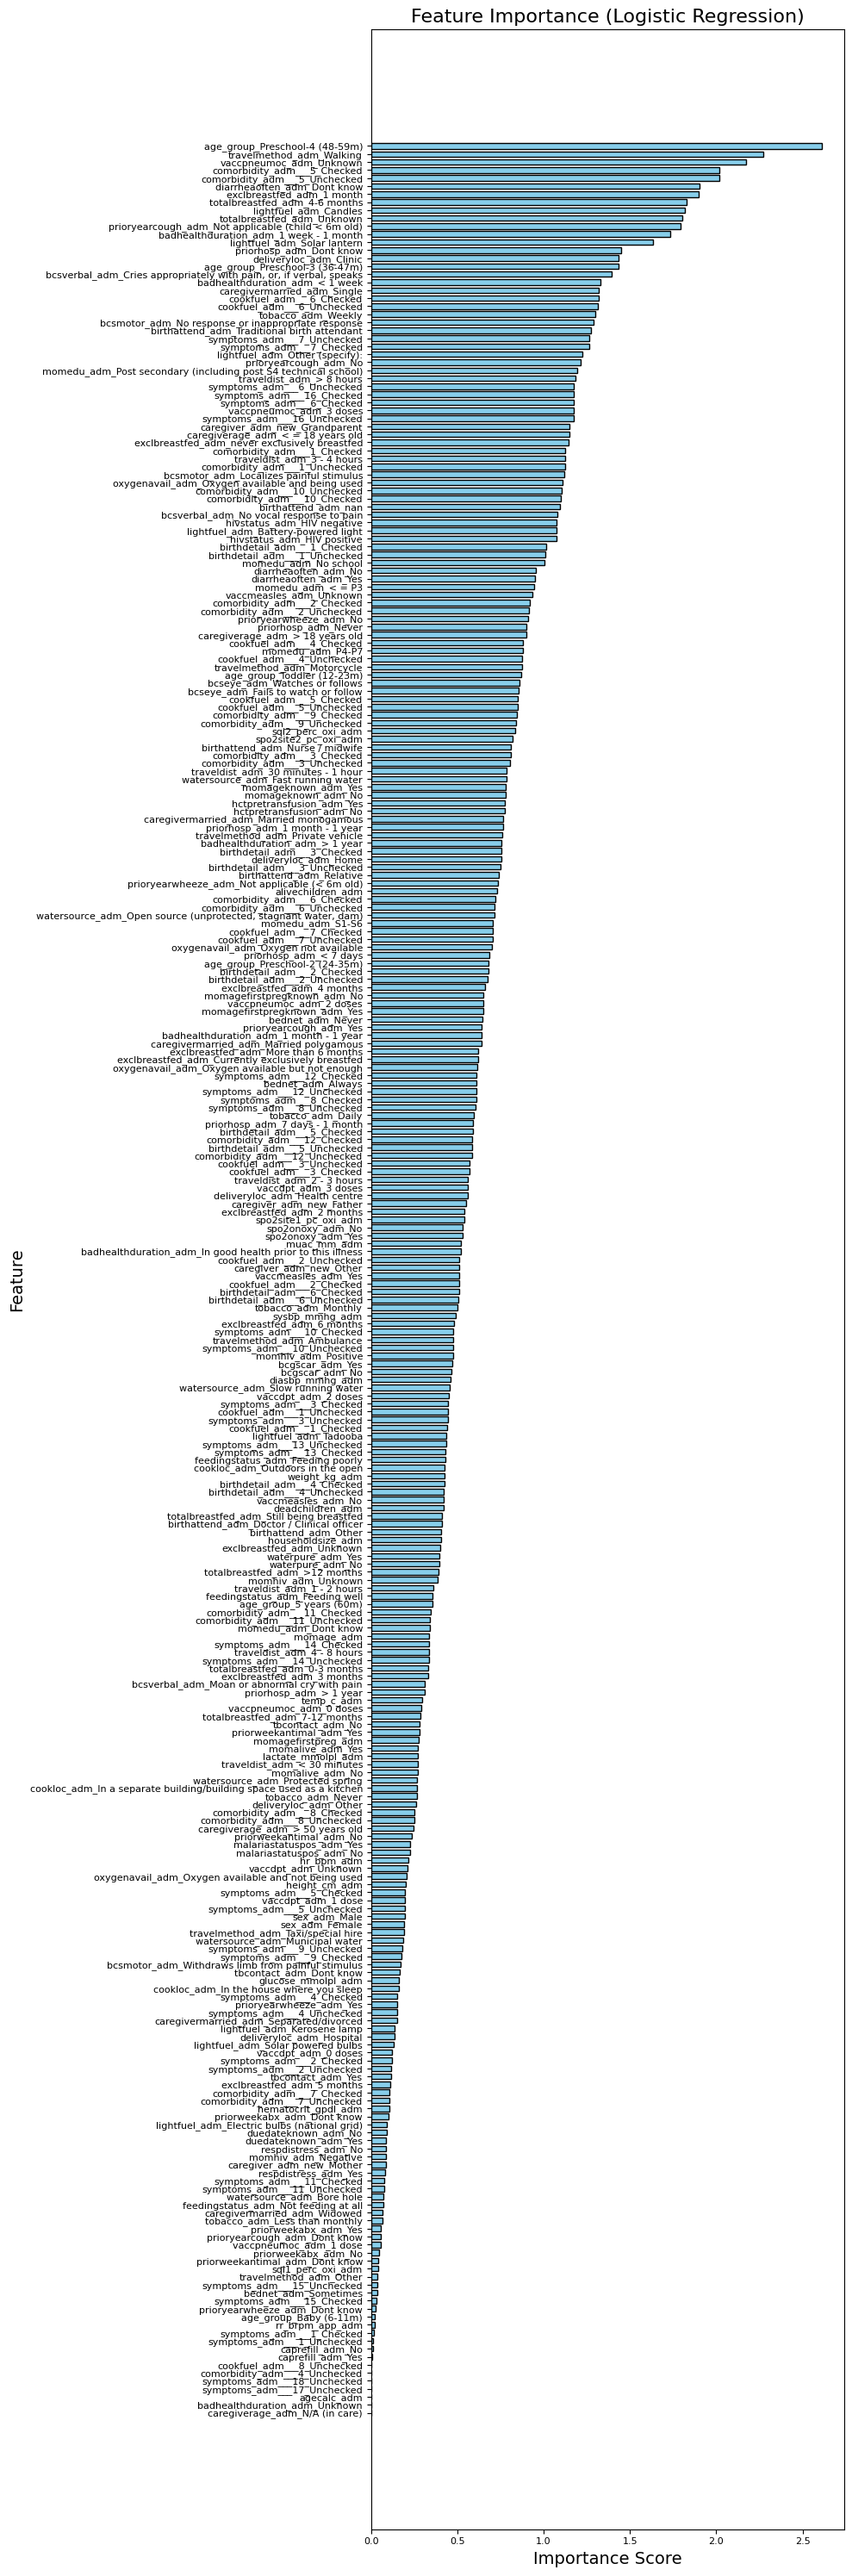

In [82]:
# Get the coefficients (feature importance)
coefficients = model.coef_[0]  # For binary classification, use model.coef_[0]
feature_importance = np.abs(coefficients)  # Absolute value of coefficients for importance

# Print feature importance
print("Feature Importance Scores:", feature_importance)

# Create a horizontal bar plot to visualize the feature importance scores
plt.figure(figsize=(10, 30))  # Increase height of the figure for better readability

# Sort the feature importance scores and corresponding feature names
sorted_indices = np.argsort(feature_importance)
sorted_features = X_train.columns[sorted_indices]
sorted_scores = feature_importance[sorted_indices]

# Plot the feature importance
plt.barh(sorted_features, sorted_scores, color='skyblue', edgecolor='black', height=0.7)  # Adjust height for better visibility

# Rotate the feature names on the y-axis to make them more readable
plt.yticks(rotation=0, fontsize=8)  # Adjust the font size and rotation
plt.xticks(fontsize=8)  # Adjust the font size for x-axis

# Set labels and title
plt.xlabel('Importance Score', fontsize=14)
plt.ylabel('Feature', fontsize=14)
plt.title('Feature Importance (Logistic Regression)', fontsize=16)

# Optional: Change the x-axis scale to logarithmic if necessary
# plt.xscale('log')

# Show the plot
plt.tight_layout()  # This ensures there is no clipping of the labels
plt.show()

In [56]:
import pandas as pd

# Ensure model.coef_ is for the correct case (binary or multiclass)
coefficients = model.coef_[0]  # For binary classification, this will be a 1D array
feature_importance = abs(coefficients)
feature_names = transformed_X.columns.tolist()

# Create a DataFrame with feature names and their importance
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients,
    'Feature Importance': abs(coefficients)  # Absolute value of coefficients for importance
})
# Set pandas to display all rows
pd.set_option('display.max_rows', None)
# Sort by feature importance
importance_df = importance_df.sort_values(by='Feature Importance', ascending=False)
print(importance_df)



                                               Feature  Coefficient   
282                     age_group_Preschool-4 (48-59m)    -2.610743  \
188                           travelmethod_adm_Walking    -2.271606   
50                             vaccpneumoc_adm_Unknown    -2.172241   
103                        comorbidity_adm___5_Checked    -2.017972   
104                      comorbidity_adm___5_Unchecked     2.015335   
133                        diarrheaoften_adm_Dont know     1.902098   
142                          exclbreastfed_adm_1 month     1.899959   
153                      totalbreastfed_adm_4-6 months     1.829355   
253                              lightfuel_adm_Candles     1.817768   
157                         totalbreastfed_adm_Unknown    -1.804273   
131  prioryearcough_adm_Not applicable (child < 6m ...     1.794096   
197             badhealthduration_adm_1 week - 1 month    -1.735214   
257                        lightfuel_adm_Solar lantern    -1.631636   
123   

C:\Users\asmaa\anaconda3\envs\test_env\lib\site-packages\sklearn\linear_model\_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\Users\asmaa\anaconda3\envs\test_env\lib\site-packages\sklearn\linear_model\_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#l

Best Parameters:  {'C': 100}
Best Score:  0.9230381224377826
Training Accuracy: 0.9361909400876766
Testing Accuracy: 0.8327137546468402
f1_score: 0.15384615384615383
Classification Report (Default Threshold):
              precision    recall  f1-score   support

           0       0.96      0.86      0.91       514
           1       0.08      0.25      0.12        24

    accuracy                           0.83       538
   macro avg       0.52      0.55      0.51       538
weighted avg       0.92      0.83      0.87       538



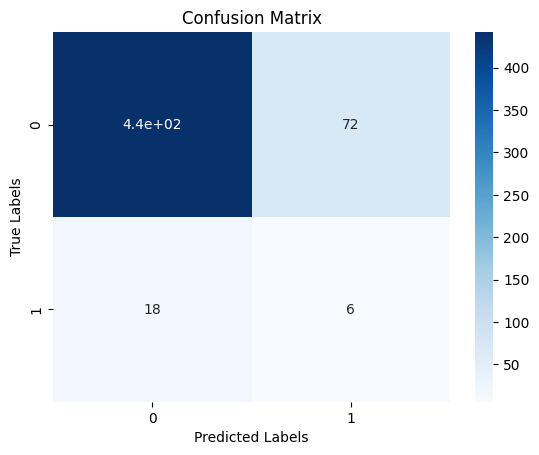

In [13]:
# Define the parameter grid
param_grid = [
    {'penalty': ['elasticnet', 'l1', 'l2']},
    {'C': [0.001, 0.01, 0.1, 1, 10, 100]}
]

# Create the random forest classifier
model = LogisticRegression(random_state=42, max_iter = 1000)

# defining scoring metric
scorer = make_scorer(f1_score)

# Create the GridSearchCV object
grid_search = GridSearchCV(estimator=model, param_grid=param_grid,scoring=scorer, cv=10)

# Fit the grid search to the training data
grid_search.fit(X_train, y_train)

# Print the best parameters and best score
print("Best Parameters: ", grid_search.best_params_)
print("Best Score: ", grid_search.best_score_)

# Get the best model
best_model = grid_search.best_estimator_

# Calculate the training accuracy of the best model
train_accuracy = best_model.score(X_train, y_train)
print("Training Accuracy:", train_accuracy)

# Calculate the testing accuracy of the best model
test_accuracy = best_model.score(X_test, y_test)
print("Testing Accuracy:", test_accuracy)

# Calculate the f1_score
f1=f1_score(y_test, y_pred)
print("f1_score:", f1)

# Make predictions on the testing data
y_pred = best_model.predict(X_test)
#Classification Report
print("Classification Report (Default Threshold):")
print(classification_report(y_test, y_pred))
# Plot the confusion matrix
confusion_mat = confusion_matrix(y_test, y_pred)
sns.heatmap(confusion_mat, annot=True, cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()

In [14]:
#Random Forrest

Training Accuracy: 1.0
Testing Accuracy: 0.9572490706319703
f1_score: 0.07999999999999999
Classification Report (Default Threshold):
              precision    recall  f1-score   support

           0       0.96      1.00      0.98       514
           1       1.00      0.04      0.08        24

    accuracy                           0.96       538
   macro avg       0.98      0.52      0.53       538
weighted avg       0.96      0.96      0.94       538



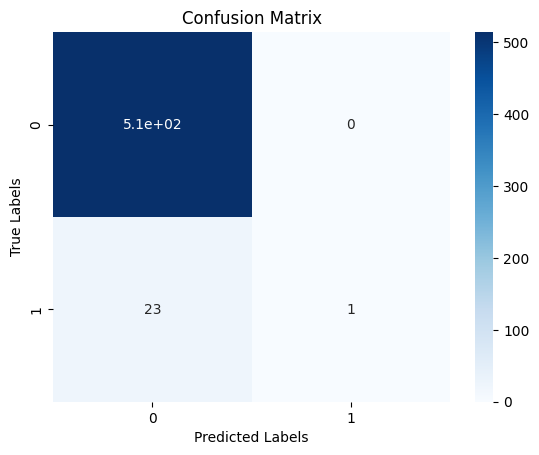

In [58]:
# Modeling
model = RandomForestClassifier(n_estimators=500)
model.fit(X_train, y_train)

# Calculate the training accuracy
train_accuracy = model.score(X_train, y_train)
print("Training Accuracy:", train_accuracy)

# Calculate the testing accuracy
test_accuracy = model.score(X_test, y_test)
print("Testing Accuracy:", test_accuracy)

# Make predictions on the testing data
y_pred = model.predict(X_test)

# Calculate the f1_score
f1=f1_score(y_test, y_pred)
print("f1_score:", f1)

# Make predictions on the testing data
y_pred = model.predict(X_test)
#Classification Report
print("Classification Report (Default Threshold):")
print(classification_report(y_test, y_pred))
# Plot the confusion matrix
confusion_mat = confusion_matrix(y_test, y_pred)
sns.heatmap(confusion_mat, annot=True, cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.show()

[7.59438763e-03 9.98353020e-03 9.07360104e-03 1.07918707e-02
 4.10665210e-03 5.10861944e-03 4.27853346e-03 3.89718729e-03
 5.75650227e-03 4.89605740e-03 4.45918387e-03 6.38937861e-03
 4.96561373e-03 4.83606314e-03 6.78649620e-03 5.92209170e-03
 3.92483551e-03 1.68385191e-02 3.90647581e-03 3.22202592e-03
 4.58972119e-03 4.02791178e-03 3.25784285e-03 3.01537760e-02
 2.81272809e-02 2.66066432e-02 2.41156026e-02 6.15646266e-04
 2.32224860e-04 7.65351039e-03 7.13454785e-03 1.88846048e-03
 1.92262913e-03 2.71386753e-02 2.61022551e-02 2.80484033e-02
 1.07679816e-02 9.28452462e-03 2.97111022e-02 1.29987386e-02
 6.70530546e-03 8.21470302e-03 8.90180561e-03 4.60648574e-03
 1.58175574e-04 4.51007482e-03 3.12770506e-04 6.06215100e-04
 5.86272860e-03 3.24064719e-03 2.51194217e-04 3.68046495e-04
 5.05685647e-04 4.82119319e-03 3.91797666e-03 3.13516966e-04
 2.60172065e-04 7.85871896e-03 8.41695025e-03 1.27429255e-04
 6.86365000e-03 6.96092361e-03 1.23760330e-03 1.32236940e-03
 4.46514372e-03 5.023493

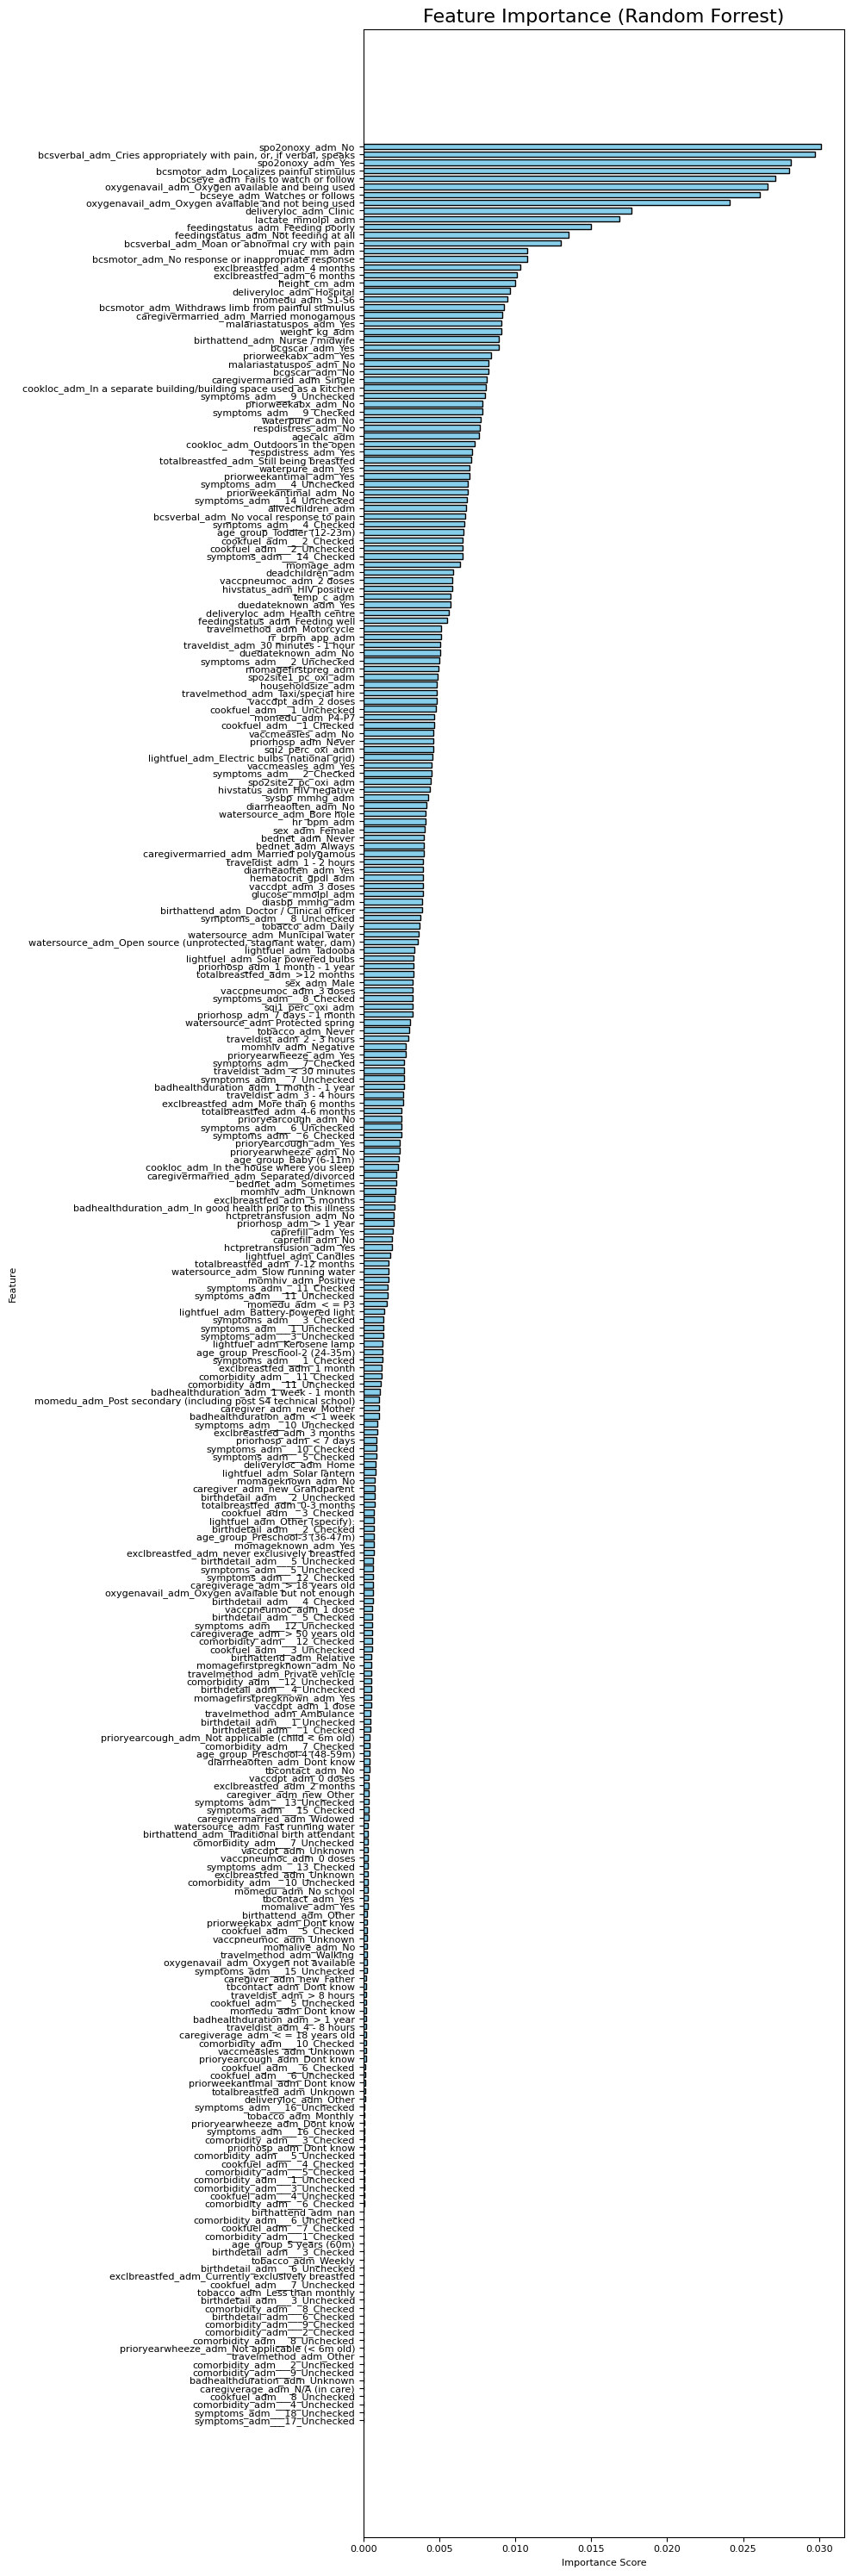

In [74]:
#feature importance score and plot them
feature_importance = model.feature_importances_
print(feature_importance)

# Create a horizontal bar plot to visualize the feature importance scores
plt.figure(figsize=(10, 30))  # Increase height of the figure for better readability

# Sort the feature importance scores and corresponding feature names
sorted_indices = np.argsort(feature_importance)
sorted_features = X_train.columns[sorted_indices]
sorted_scores = feature_importance[sorted_indices]

# Plot the feature importance
plt.barh(sorted_features, sorted_scores, color='skyblue', edgecolor='black', height=0.7)  # Adjust height for better visibility

# Rotate the feature names on the y-axis to make them more readable
plt.yticks(rotation=0, fontsize=8)  # Adjust the font size and rotation
plt.xticks(fontsize=8)  # Adjust the font size for x-axis


# Set labels and title
plt.xlabel('Importance Score', fontsize=8)
plt.ylabel('Feature', fontsize=8)
plt.title('Feature Importance (Random Forrest)', fontsize=16)

# Optional: Change the x-axis scale to logarithmic if necessary
# plt.xscale('log')

# Show the plot
plt.tight_layout()  # This ensures there is no clipping of the labels
plt.show()